# Problem 1 — Regularization to Avoid Overfitting
Build a neural network for binary classification and investigate how *regularization techniques help reduce overfitting.*

### Dataset
Breast Cancer Wisconsin Diagnostic Dataset. [Data link](https://github.com/shekharkumar1412-cpu/Teaching\_Content/blob/main/MCA\_Rungta/DL/Practice\_Problems/Breast\_Cancer\_Dataset.csv)

### A. Data Understanding
After loading the dataset:
* Display shape.
* Display head().
* Display data types.
* Generate summary statistics.
* Check for missing values.
* Check the target/class distribution.
* Identify and remove unnecessary columns such as ID.
* Convert the target variable into numerical form.
* Separate X and y.

### B. Preprocessing
* Perform train-test split.
* Apply feature scaling.
* Use an appropriate scaler.
* Make sure the scaler is fitted only on the training data.

### C. Baseline Neural Network
Build a relatively large neural network *without regularization.*
Use:
* Binary Cross Entropy
* Suitable optimizer
* Appropriate output activation

Train for a sufficiently large number of epochs.

### D. Identify Overfitting
Plot:
1.​ Training loss vs validation loss
2.​ Training accuracy vs validation accuracy

### E. L2 Regularization
Add L2 regularization to the Dense layers.
Experiment with:
λ = 0
λ = 0.001
λ = 0.01

## F. Dropout Regularization
Now experiment with:
Dropout = 0
Dropout = 0.2
Dropout = 0.5

Compare the three models.

(569, 32)
   Unnamed: 0  x.radius_mean  x.texture_mean  x.perimeter_mean  x.area_mean  \
0           1         13.540           14.36             87.46        566.3   
1           2         13.080           15.71             85.63        520.0   
2           3          9.504           12.44             60.34        273.9   
3           4         13.030           18.42             82.61        523.8   
4           5          8.196           16.84             51.71        201.9   

   x.smoothness_mean  x.compactness_mean  x.concavity_mean  \
0            0.09779             0.08129           0.06664   
1            0.10750             0.12700           0.04568   
2            0.10240             0.06492           0.02956   
3            0.08983             0.03766           0.02562   
4            0.08600             0.05943           0.01588   

   x.concave_pts_mean  x.symmetry_mean  ...  x.texture_worst  \
0            0.047810           0.1885  ...            19.26   
1            0

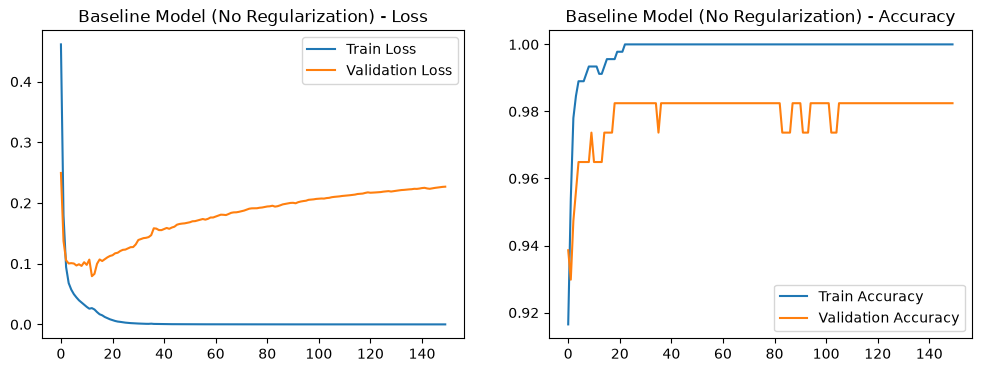

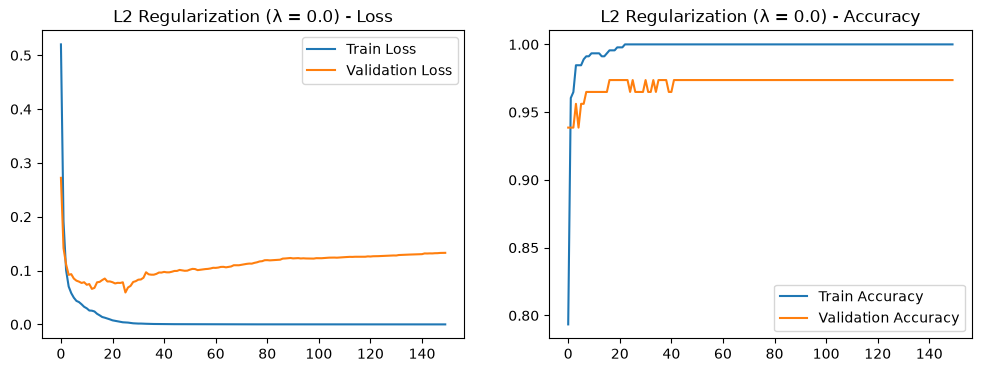

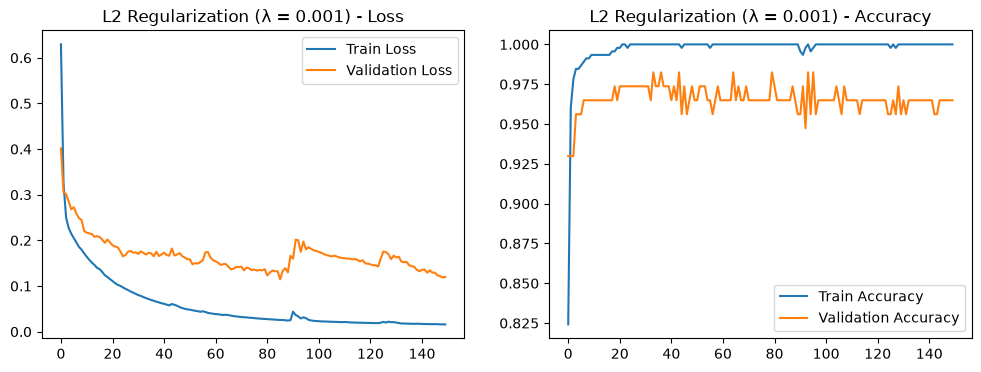

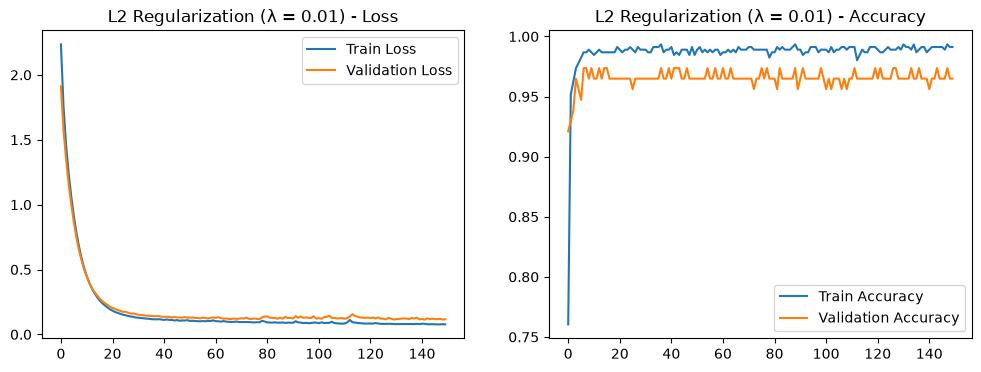

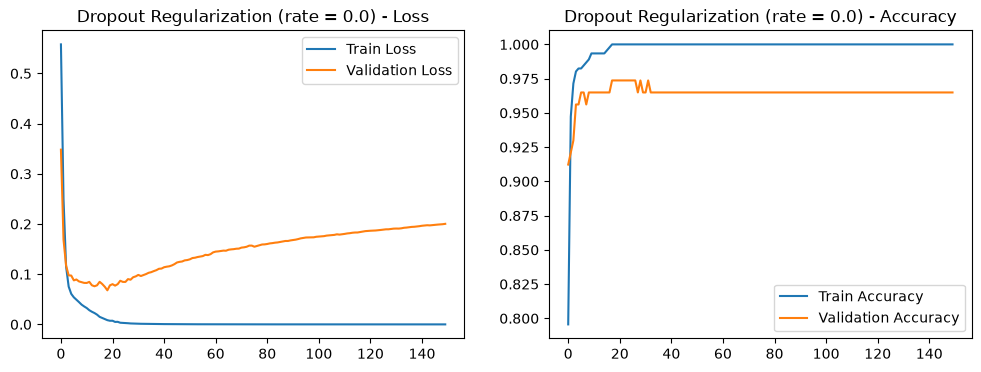

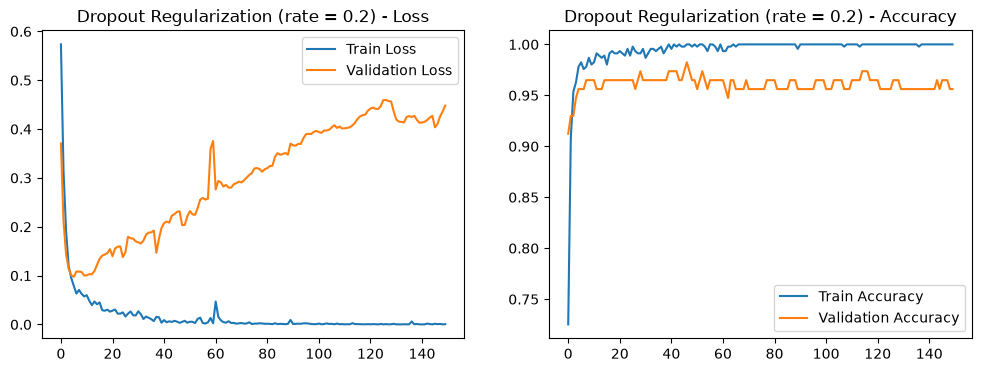

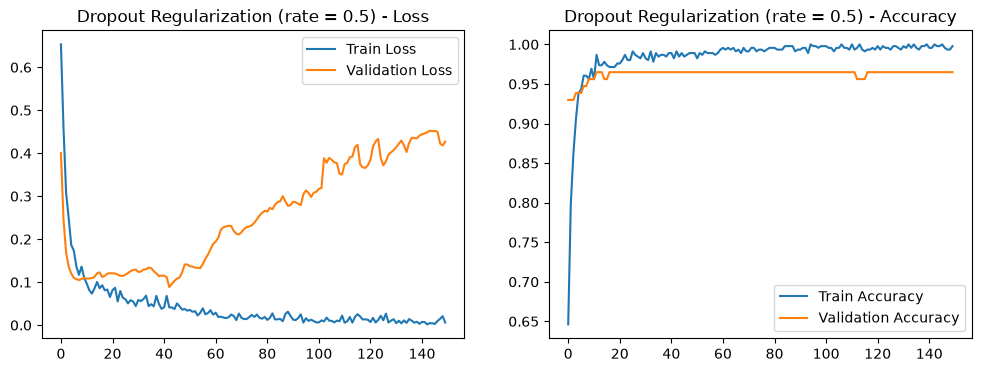

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.regularizers import l2

df = pd.read_csv('Breast_Cancer_Dataset.csv')

print(df.shape)
print(df.head())
print(df.dtypes)
print(df.describe())
print(df.isnull().sum())
print(df['y'].value_counts())

if df.columns[0].startswith('Unnamed') or df.columns[0] == '':
    df = df.drop(df.columns[0], axis=1)
df['y'] = df['y'].map({'M': 1, 'B': 0})

X = df.drop('y', axis=1)
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

def plot_metrics(history, title):
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{title} - Loss')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'{title} - Accuracy')
    plt.legend()
    
    plt.show()

input_dim = X_train_scaled.shape[1]

base_model = Sequential()
base_model.add(Input(shape=(input_dim,)))
base_model.add(Dense(128, activation='relu'))
base_model.add(Dense(64, activation='relu'))
base_model.add(Dense(32, activation='relu'))
base_model.add(Dense(1, activation='sigmoid'))
base_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

base_history = base_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=150, batch_size=32, verbose=0)
plot_metrics(base_history, "Baseline Model (No Regularization)")

for l2_val in [0.0, 0.001, 0.01]:
    l2_model = Sequential()
    l2_model.add(Input(shape=(input_dim,)))
    l2_model.add(Dense(128, activation='relu', kernel_regularizer=l2(l2_val)))
    l2_model.add(Dense(64, activation='relu', kernel_regularizer=l2(l2_val)))
    l2_model.add(Dense(32, activation='relu', kernel_regularizer=l2(l2_val)))
    l2_model.add(Dense(1, activation='sigmoid'))
    l2_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    
    l2_history = l2_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=150, batch_size=32, verbose=0)
    plot_metrics(l2_history, f"L2 Regularization (λ = {l2_val})")

for dr in [0.0, 0.2, 0.5]:
    do_model = Sequential()
    do_model.add(Input(shape=(input_dim,)))
    do_model.add(Dense(128, activation='relu'))
    do_model.add(Dropout(dr))
    do_model.add(Dense(64, activation='relu'))
    do_model.add(Dropout(dr))
    do_model.add(Dense(32, activation='relu'))
    do_model.add(Dropout(dr))
    do_model.add(Dense(1, activation='sigmoid'))
    do_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    
    do_history = do_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=150, batch_size=32, verbose=0)
    plot_metrics(do_history, f"Dropout Regularization (rate = {dr})")

# Problem 2 — Batch Normalization
Understand how *Batch Normalization* affects neural-network training.
Use the same *Breast Cancer dataset*.

* Build a relatively large neural network without Batch Normalization
* Now Build a relatively large neural network with Batch Normalization
* Now Build a relatively large neural network with Layer Normalization
* Now Compare all three Models

* *Finally Experiment*
Train both models with the same:
    * Learning rate
    * Batch size
    * Epochs
    * Optimizer
    * Train/test split

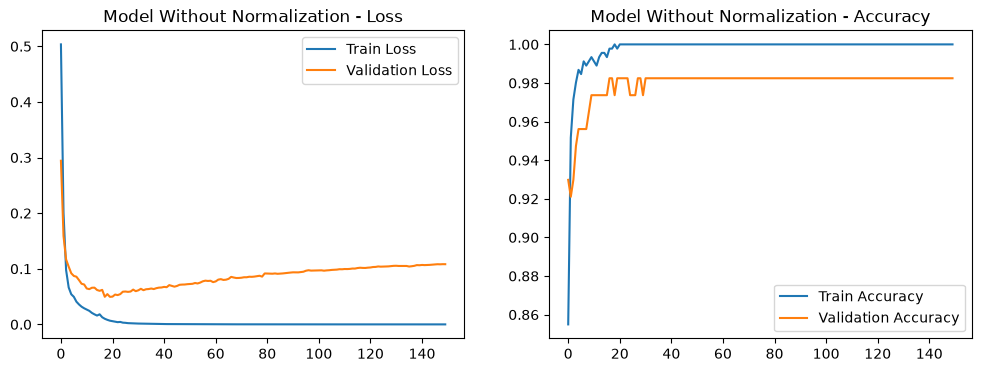

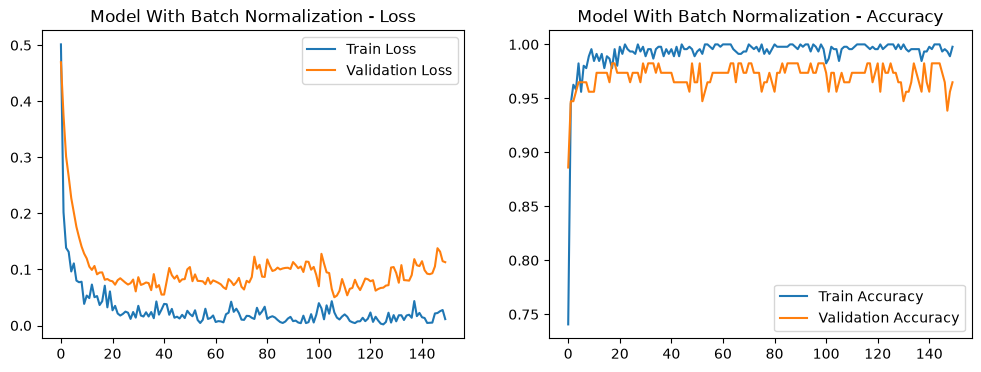

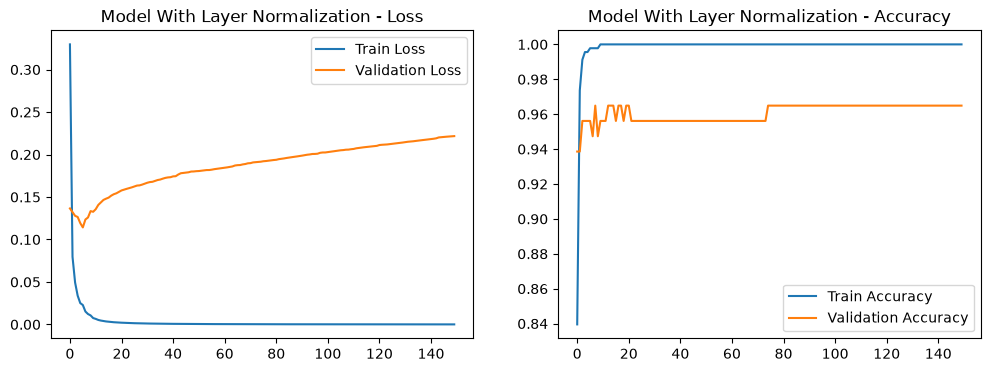

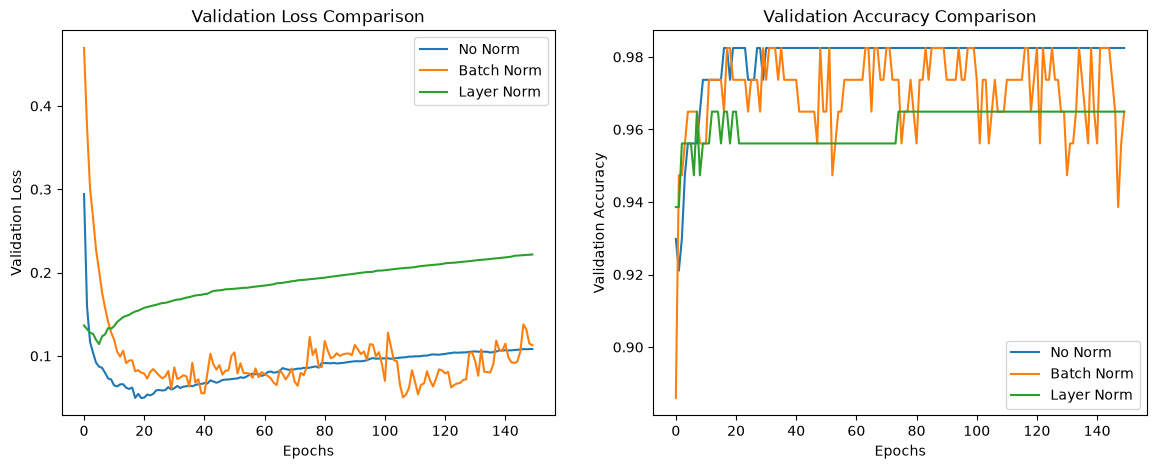

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, LayerNormalization, Input
from tensorflow.keras.optimizers import Adam

df = pd.read_csv('Breast_Cancer_Dataset.csv')

if df.columns[0].startswith('Unnamed') or df.columns[0] == '':
    df = df.drop(df.columns[0], axis=1)

df['y'] = df['y'].map({'M': 1, 'B': 0})

X = df.drop('y', axis=1)
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

def plot_metrics(history, title):
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{title} - Loss')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'{title} - Accuracy')
    plt.legend()
    
    plt.show()

learning_rate = 0.001
batch_size = 32
epochs = 150
input_dim = X_train_scaled.shape[1]

base_model = Sequential()
base_model.add(Input(shape=(input_dim,)))
base_model.add(Dense(128, activation='relu'))
base_model.add(Dense(64, activation='relu'))
base_model.add(Dense(32, activation='relu'))
base_model.add(Dense(1, activation='sigmoid'))
base_model.compile(optimizer=Adam(learning_rate=learning_rate), loss='binary_crossentropy', metrics=['accuracy'])

base_history = base_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), 
                              epochs=epochs, batch_size=batch_size, verbose=0)
plot_metrics(base_history, "Model Without Normalization")

bn_model = Sequential()
bn_model.add(Input(shape=(input_dim,)))
bn_model.add(Dense(128, activation='relu'))
bn_model.add(BatchNormalization())
bn_model.add(Dense(64, activation='relu'))
bn_model.add(BatchNormalization())
bn_model.add(Dense(32, activation='relu'))
bn_model.add(BatchNormalization())
bn_model.add(Dense(1, activation='sigmoid'))
bn_model.compile(optimizer=Adam(learning_rate=learning_rate), loss='binary_crossentropy', metrics=['accuracy'])

bn_history = bn_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), 
                          epochs=epochs, batch_size=batch_size, verbose=0)
plot_metrics(bn_history, "Model With Batch Normalization")

ln_model = Sequential()
ln_model.add(Input(shape=(input_dim,)))
ln_model.add(Dense(128, activation='relu'))
ln_model.add(LayerNormalization())
ln_model.add(Dense(64, activation='relu'))
ln_model.add(LayerNormalization())
ln_model.add(Dense(32, activation='relu'))
ln_model.add(LayerNormalization())
ln_model.add(Dense(1, activation='sigmoid'))
ln_model.compile(optimizer=Adam(learning_rate=learning_rate), loss='binary_crossentropy', metrics=['accuracy'])

ln_history = ln_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), 
                          epochs=epochs, batch_size=batch_size, verbose=0)
plot_metrics(ln_history, "Model With Layer Normalization")

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(base_history.history['val_loss'], label='No Norm')
plt.plot(bn_history.history['val_loss'], label='Batch Norm')
plt.plot(ln_history.history['val_loss'], label='Layer Norm')
plt.title('Validation Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(base_history.history['val_accuracy'], label='No Norm')
plt.plot(bn_history.history['val_accuracy'], label='Batch Norm')
plt.plot(ln_history.history['val_accuracy'], label='Layer Norm')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()

plt.show()